In [ ]:
# =============================================================================
# KAGGLE AUTHENTICATION & DATASET DOWNLOAD
# =============================================================================


!pip install -q kaggle

import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

!kaggle datasets download -d tawsifurrahman/covid19-radiography-database \
    --unzip -p /content/dataset --quiet

print("✅ Dataset downloaded successfully.")

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
✅ Dataset downloaded successfully.


In [ ]:
# =============================================================================
# CELL 2: IMPORT ALL LIBRARIES
# =============================================================================
"""
We import everything upfront for clarity:
- torch / torchvision: Deep learning framework & pre-trained models
- PIL: Image loading
- sklearn: Medical-grade evaluation metrics (Precision, Recall, F1)
- matplotlib / seaborn: Visualization of confusion matrices and predictions
- numpy: Numerical operations
- pathlib / shutil / random: File system operations and reproducibility
"""

import os
import random
import shutil
import copy
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split, Subset

import torchvision
from torchvision import transforms, models
from torchvision.datasets import ImageFolder

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
)

warnings.filterwarnings("ignore")

# -----------------------------------------------------------------------------
# CRUCIAL: Device-agnostic code
# This ensures the code runs on GPU if available, otherwise falls back to CPU.
# In Colab: Runtime → Change runtime type → GPU (T4 recommended)
# -----------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Using device: {device}")
if device.type == "cuda":
    print(f"   GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# Reproducibility — critical in medical research for result verification
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("✅ Cell 2 Complete: All libraries imported, device configured.")

🖥️  Using device: cuda
   GPU Name: Tesla T4
   GPU Memory: 15.8 GB
✅ Cell 2 Complete: All libraries imported, device configured.


In [ ]:
# =============================================================================
# CELL 3: DATA ORGANIZATION
# =============================================================================
"""
The Kaggle dataset has multiple classes (COVID, Normal, Lung Opacity, Viral Pneumonia).
For our BINARY CLASSIFICATION task, we only need:
  - Class 0: Normal
  - Class 1: COVID

We'll reorganize the data into an ImageFolder-compatible structure:
  /content/organized_data/
      Normal/
          img1.png, img2.png, ...
      COVID/
          img1.png, img2.png, ...
"""

# Paths — adjust these if your download location differs
DATASET_ROOT = Path("/content/dataset/COVID-19_Radiography_Dataset")
ORGANIZED_ROOT = Path("/content/organized_data")

# The dataset stores images and masks in separate folders.
# We only need the images (not the masks).
CLASS_MAP = {
    "COVID": "COVID",       # Source folder name → Target class name
    "Normal": "Normal",
}

def organize_dataset(source_root: Path, target_root: Path, class_map: dict, max_per_class: int = None):
    """
    Copies images from the Kaggle dataset structure into a flat ImageFolder structure.

    Why limit max_per_class?
    - The Normal class has ~10,000+ images while COVID has ~3,600.
    - Severe class imbalance hurts model training. We balance by capping both classes.
    - In a production setting, you'd use weighted sampling or focal loss instead.

    Args:
        source_root: Path to the downloaded Kaggle dataset.
        target_root: Path where organized data will be stored.
        class_map: Mapping from source folder names to target class names.
        max_per_class: Maximum images per class (for balancing). None = use all.
    """
    if target_root.exists():
        shutil.rmtree(target_root)
        print(f"   Cleaned existing directory: {target_root}")

    total_copied = 0

    for source_name, target_name in class_map.items():
        source_dir = source_root / source_name / "images"

        # Fallback: some versions of the dataset don't have an 'images' subfolder
        if not source_dir.exists():
            source_dir = source_root / source_name

        target_dir = target_root / target_name
        target_dir.mkdir(parents=True, exist_ok=True)

        # Gather all image files
        image_files = sorted([
            f for f in source_dir.iterdir()
            if f.suffix.lower() in (".png", ".jpg", ".jpeg")
        ])

        # Cap the number if requested (for class balancing)
        if max_per_class is not None:
            image_files = image_files[:max_per_class]

        for img_file in image_files:
            shutil.copy2(img_file, target_dir / img_file.name)

        total_copied += len(image_files)
        print(f"   {target_name}: {len(image_files)} images copied")

    print(f"\n   Total images organized: {total_copied}")
    return total_copied


# Balance classes: use 3,600 images per class (COVID has ~3,616)
print("📂 Organizing dataset into binary classification structure...")
organize_dataset(DATASET_ROOT, ORGANIZED_ROOT, CLASS_MAP, max_per_class=3600)
print("✅ Cell 3 Complete: Dataset organized.")

📂 Organizing dataset into binary classification structure...
   COVID: 3600 images copied
   Normal: 3600 images copied

   Total images organized: 7200
✅ Cell 3 Complete: Dataset organized.


In [ ]:
# =============================================================================
# CELL 4: DATA TRANSFORMS & DATASET CREATION
# =============================================================================
"""
WHY THESE SPECIFIC TRANSFORMS?

1. Resize(224, 224):
   - ResNet18 was originally trained on 224×224 ImageNet images.
   - Using the same resolution means the pre-trained filters operate at the
     spatial scale they were optimized for.

2. ToTensor():
   - Converts PIL Image (H, W, C) with values [0, 255] to
     PyTorch Tensor (C, H, W) with values [0.0, 1.0].

3. Normalize(mean, std) with ImageNet statistics:
   - The pre-trained ResNet weights expect inputs normalized to the same
     distribution they were trained on.
   - If we skip this, the activations in early layers will be way off,
     and transfer learning will perform poorly.
   - mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225] are the
     channel-wise statistics of ImageNet.

4. Data Augmentation (TRAIN ONLY):
   - RandomHorizontalFlip: X-rays can be mirrored without losing diagnostic info.
   - RandomRotation(10): Slight rotation simulates real-world positioning variance.
   - ColorJitter: Small brightness/contrast changes simulate different X-ray machines.
   - We do NOT augment validation/test sets — they must represent real-world input.
"""

# Training transforms include augmentation to improve generalization
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Validation/Test transforms — no augmentation, only preprocessing
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Load the full dataset using ImageFolder
# ImageFolder automatically assigns labels based on folder names (alphabetical):
#   COVID → 0, Normal → 1
# We'll verify and potentially remap below.
full_dataset = ImageFolder(root=str(ORGANIZED_ROOT))

# Check class mapping
print(f"📋 Class-to-Index mapping: {full_dataset.class_to_idx}")
print(f"   Total images: {len(full_dataset)}")

# We need the class names for later visualization
CLASS_NAMES = full_dataset.classes  # ['COVID', 'Normal']
NUM_CLASSES = len(CLASS_NAMES)
print(f"   Classes: {CLASS_NAMES}")

print("✅ Cell 4 Complete: Transforms and dataset defined.")

📋 Class-to-Index mapping: {'COVID': 0, 'Normal': 1}
   Total images: 7200
   Classes: ['COVID', 'Normal']
✅ Cell 4 Complete: Transforms and dataset defined.


In [ ]:
# =============================================================================
# CELL 5: TRAIN / VALIDATION / TEST SPLIT
# =============================================================================
"""
Split: 80% Train, 10% Validation, 10% Test

WHY this specific split?
- 80% for training gives the model enough data to learn robust features.
- 10% validation is used for early stopping & hyperparameter decisions.
  The model NEVER trains on this data, so it gives an unbiased estimate
  of performance during training.
- 10% test is held out completely until the very end. This is the
  "real-world" performance estimate we report in a medical paper.

WHY we use Subset + separate transforms:
- random_split returns Subsets that share the parent dataset's transform.
- We need DIFFERENT transforms for train (with augmentation) vs eval (without).
- Solution: Create wrapper datasets that override the transform.
"""

# Calculate split sizes
total_size = len(full_dataset)
train_size = int(0.80 * total_size)
val_size = int(0.10 * total_size)
test_size = total_size - train_size - val_size  # Remainder goes to test

print(f"📊 Dataset Split:")
print(f"   Train: {train_size} images ({train_size/total_size*100:.0f}%)")
print(f"   Val:   {val_size} images ({val_size/total_size*100:.0f}%)")
print(f"   Test:  {test_size} images ({test_size/total_size*100:.0f}%)")

# Perform the split (uses SEED for reproducibility via the generator)
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)


class TransformedSubset(Dataset):
    """
    Wraps a torch Subset to apply a custom transform.

    This is necessary because random_split creates Subsets that inherit
    the parent dataset's transform. We need different transforms for
    training (augmented) vs. evaluation (clean).
    """

    def __init__(self, subset: Subset, transform: transforms.Compose):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        # Get the raw image and label from the underlying dataset
        image, label = self.subset[idx]

        # If image is already a tensor (from parent transform), convert back to PIL
        if isinstance(image, torch.Tensor):
            # This shouldn't happen if parent has no transform, but safety first
            image = transforms.ToPILImage()(image)
        elif not isinstance(image, Image.Image):
            image = Image.fromarray(np.array(image))

        # Apply our specific transform
        image = self.transform(image)
        return image, label


# IMPORTANT: Remove the parent dataset's transform so we get raw PIL images
full_dataset.transform = None

# Create transformed datasets
train_dataset = TransformedSubset(train_subset, train_transforms)
val_dataset = TransformedSubset(val_subset, eval_transforms)
test_dataset = TransformedSubset(test_subset, eval_transforms)

# Verify a sample
sample_img, sample_label = train_dataset[0]
print(f"\n   Sample tensor shape: {sample_img.shape}")  # Should be (3, 224, 224)
print(f"   Sample label: {sample_label} ({CLASS_NAMES[sample_label]})")
print(f"   Pixel value range: [{sample_img.min():.3f}, {sample_img.max():.3f}]")

print("✅ Cell 5 Complete: Data split into Train/Val/Test.")

📊 Dataset Split:
   Train: 5760 images (80%)
   Val:   720 images (10%)
   Test:  720 images (10%)

   Sample tensor shape: torch.Size([3, 224, 224])
   Sample label: 1 (Normal)
   Pixel value range: [-1.964, 2.379]
✅ Cell 5 Complete: Data split into Train/Val/Test.


In [ ]:
# =============================================================================
# CELL 6: CREATE DATALOADERS
# =============================================================================
"""
DataLoaders handle:
- Batching: Groups images into batches of 32 for efficient GPU computation.
- Shuffling: Randomizes training order each epoch to prevent the model from
  memorizing the sequence (only for training).
- Parallel Loading: num_workers=2 uses 2 CPU threads to pre-load batches
  while the GPU processes the current batch (pipeline parallelism).
- pin_memory: Pre-allocates tensors in page-locked memory for faster
  CPU→GPU transfer. Only useful when training on GPU.
"""

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,  # Shuffle training data every epoch
    num_workers=NUM_WORKERS,
    pin_memory=True if device.type == "cuda" else False,
    drop_last=True,  # Drop incomplete last batch to keep batch norm stable
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,  # Never shuffle validation — order doesn't matter
    num_workers=NUM_WORKERS,
    pin_memory=True if device.type == "cuda" else False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,  # Never shuffle test set
    num_workers=NUM_WORKERS,
    pin_memory=True if device.type == "cuda" else False,
)

# Quick verification: peek at one batch
images, labels = next(iter(train_loader))
print(f"📦 Batch shape: {images.shape}")  # [32, 3, 224, 224]
print(f"   Labels shape: {labels.shape}")  # [32]
print(f"   Labels in batch: {labels.tolist()}")
print(f"   Unique labels: {torch.unique(labels).tolist()}")

print("✅ Cell 6 Complete: DataLoaders ready.")

📦 Batch shape: torch.Size([32, 3, 224, 224])
   Labels shape: torch.Size([32])
   Labels in batch: [1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0]
   Unique labels: [0, 1]
✅ Cell 6 Complete: DataLoaders ready.


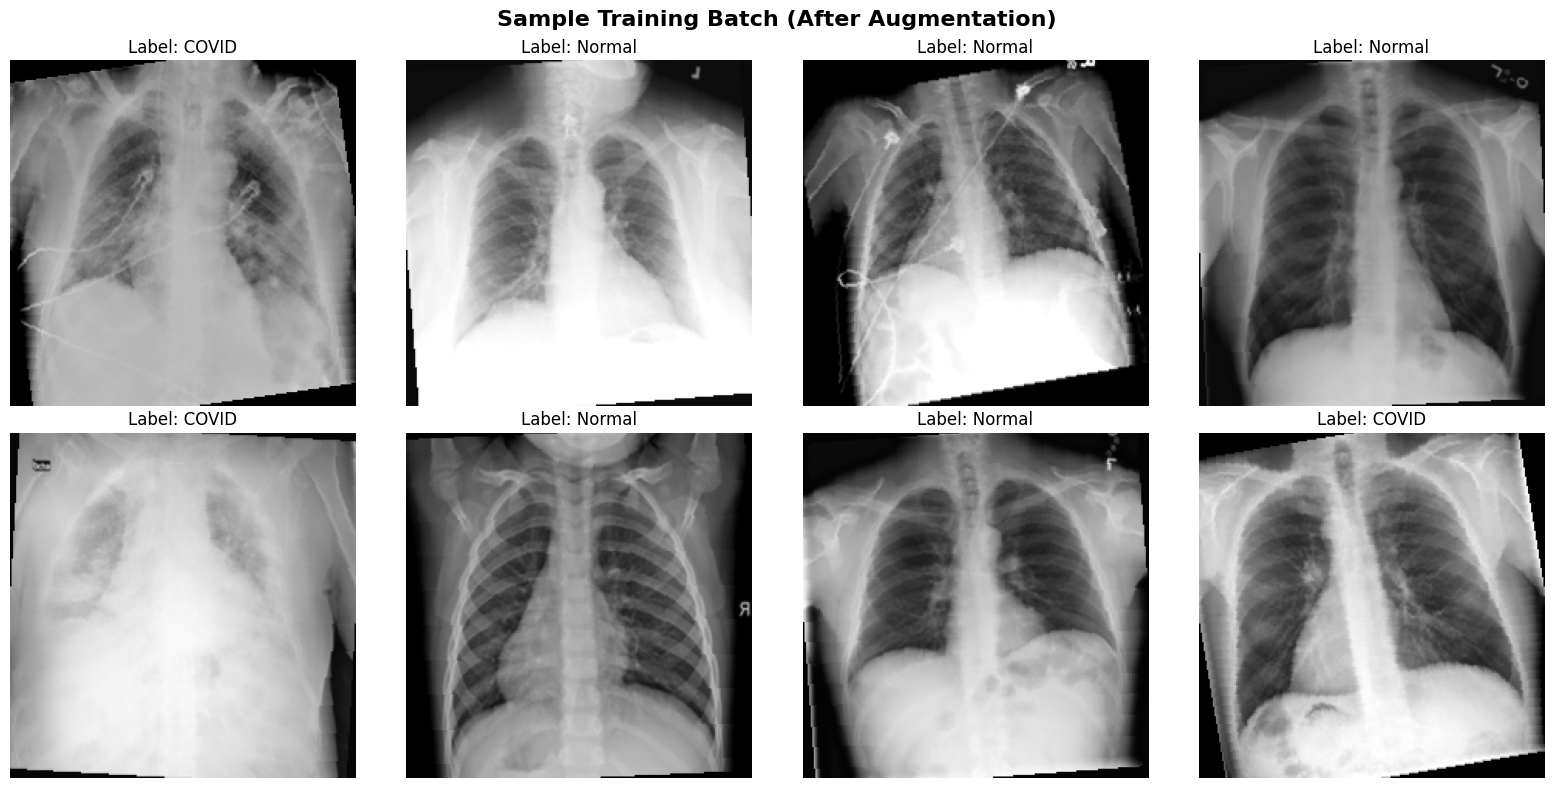

✅ Cell 7 Complete: Data visualization done.


In [ ]:
# =============================================================================
# CELL 7: VISUALIZE A TRAINING BATCH
# =============================================================================
"""
Always visually verify your data pipeline before training.
This catches issues like:
- Incorrect normalization (images look washed out or clipped)
- Wrong labels (COVID labeled as Normal)
- Broken augmentation (images are black or corrupted)
"""

def denormalize(tensor, mean, std):
    """
    Reverse the ImageNet normalization for visualization.
    The model sees normalized tensors, but humans need [0, 1] range.
    """
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean


def show_batch(dataloader, class_names, num_images=8):
    """Display a grid of images from a single batch."""
    images, labels = next(iter(dataloader))

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle("Sample Training Batch (After Augmentation)", fontsize=16, fontweight="bold")

    for idx, ax in enumerate(axes.flat):
        if idx >= num_images or idx >= len(images):
            ax.axis("off")
            continue

        # Denormalize for display
        img = denormalize(images[idx], [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        img = img.clamp(0, 1)  # Clip to valid range
        img = img.permute(1, 2, 0).numpy()  # (C, H, W) → (H, W, C)

        ax.imshow(img)
        ax.set_title(f"Label: {class_names[labels[idx]]}", fontsize=12)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_batch(train_loader, CLASS_NAMES)
print("✅ Cell 7 Complete: Data visualization done.")

In [ ]:
# =============================================================================
# CELL 8: MODEL ARCHITECTURE — TRANSFER LEARNING WITH ResNet18
# =============================================================================
"""
WHY TRANSFER LEARNING?

Medical imaging datasets are typically small (thousands, not millions of images).
Training a deep CNN from scratch on such data leads to severe overfitting.

Transfer Learning solution:
1. Start with ResNet18 pre-trained on ImageNet (1.4M images, 1000 classes).
2. The early layers have learned universal visual features:
   - Layer 1: Edges, gradients
   - Layer 2: Textures, patterns
   - Layer 3: Object parts
   - Layer 4: High-level semantic features
3. These features are useful for X-ray analysis too (edges of lungs,
   texture of ground-glass opacities, etc.)
4. We FREEZE early layers (don't update their weights) to:
   - Preserve learned features
   - Dramatically reduce training time
   - Prevent overfitting on our small dataset
5. We REPLACE the final FC layer (originally 512→1000 for ImageNet)
   with a new layer (512→2 for our binary classification).
6. We UNFREEZE layer4 (the last conv block) for fine-tuning:
   - This allows the model to adapt high-level features to medical images
   - while keeping low-level feature extractors intact.
"""


def build_model(num_classes: int = 2, freeze_backbone: bool = True) -> nn.Module:
    """
    Builds a ResNet18 model with transfer learning configuration.

    Args:
        num_classes: Number of output classes (2 for binary).
        freeze_backbone: Whether to freeze early layers.

    Returns:
        Configured ResNet18 model.
    """
    # Load pre-trained ResNet18 (weights trained on ImageNet)
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        # Step 1: Freeze ALL parameters first
        for param in model.parameters():
            param.requires_grad = False

        # Step 2: Unfreeze layer4 (last convolutional block) for fine-tuning
        # This block captures high-level features that benefit from adaptation
        # to the medical domain
        for param in model.layer4.parameters():
            param.requires_grad = True

    # Step 3: Replace the final fully connected layer
    # Original: Linear(512, 1000) for ImageNet
    # New:      Linear(512, 2) for our binary task
    num_features = model.fc.in_features  # 512 for ResNet18
    model.fc = nn.Sequential(
        nn.Dropout(p=0.5),  # Dropout for regularization (prevent overfitting)
        nn.Linear(num_features, num_classes)
    )

    return model


# Build and move model to device
model = build_model(num_classes=NUM_CLASSES, freeze_backbone=True)
model = model.to(device)

# Print model summary: count trainable vs frozen parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print("🧠 Model Architecture: ResNet18 (Transfer Learning)")
print(f"   Total parameters:     {total_params:>10,}")
print(f"   Trainable parameters: {trainable_params:>10,} ({trainable_params/total_params*100:.1f}%)")
print(f"   Frozen parameters:    {frozen_params:>10,} ({frozen_params/total_params*100:.1f}%)")
print(f"\n   Final classifier: {model.fc}")

# Verify model works with a dummy input
dummy_input = torch.randn(1, 3, 224, 224).to(device)
dummy_output = model(dummy_input)
print(f"\n   Dummy input shape:  {dummy_input.shape}")
print(f"   Dummy output shape: {dummy_output.shape}")  # Should be [1, 2]

print("✅ Cell 8 Complete: Model built and moved to device.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 97.1MB/s]


🧠 Model Architecture: ResNet18 (Transfer Learning)
   Total parameters:     11,177,538
   Trainable parameters:  8,394,754 (75.1%)
   Frozen parameters:     2,782,784 (24.9%)

   Final classifier: Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=512, out_features=2, bias=True)
)

   Dummy input shape:  torch.Size([1, 3, 224, 224])
   Dummy output shape: torch.Size([1, 2])
✅ Cell 8 Complete: Model built and moved to device.


In [ ]:
# =============================================================================
# CELL 9: TRAINING CONFIGURATION
# =============================================================================
"""
LOSS FUNCTION: CrossEntropyLoss
- Standard for multi-class (and binary) classification with PyTorch.
- Combines LogSoftmax + NLLLoss in a numerically stable way.
- Expects raw logits (not softmax outputs), which is what our model produces.

OPTIMIZER: Adam with lr=1e-4
- Adam adapts learning rates per-parameter, which is great for transfer learning
  where different layers may need different update magnitudes.
- lr=1e-4 is conservative (lower than default 1e-3) because:
  a) Pre-trained weights are already close to a good solution
  b) Large learning rates can destroy pre-trained features ("catastrophic forgetting")

EARLY STOPPING:
- Monitors validation accuracy after each epoch.
- Saves the model whenever validation accuracy improves ("best_model.pth").
- If val accuracy doesn't improve for `patience` epochs, training stops.
- This prevents overfitting: the model that generalized best is saved.
- Critical in medical AI where overfitting = false confidence in diagnosis.
"""

# Hyperparameters
NUM_EPOCHS = 20
LEARNING_RATE = 1e-4
PATIENCE = 5  # Early stopping patience (epochs without improvement)
BEST_MODEL_PATH = "/content/best_model.pth"

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer — only optimize parameters that require gradients
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=1e-5  # L2 regularization to reduce overfitting
)

# Learning rate scheduler — reduces LR when validation loss plateaus

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",       # We're monitoring accuracy (higher is better)
    factor=0.5,       # Halve the LR when triggered
    patience=3,       # Wait 3 epochs before reducing
    min_lr=1e-7
)

print("⚙️  Training Configuration:")
print(f"   Epochs:        {NUM_EPOCHS}")
print(f"   Batch Size:    {BATCH_SIZE}")
print(f"   Learning Rate: {LEARNING_RATE}")
print(f"   Optimizer:     Adam (weight_decay=1e-5)")
print(f"   Loss:          CrossEntropyLoss")
print(f"   Scheduler:     ReduceLROnPlateau")
print(f"   Early Stopping Patience: {PATIENCE}")

print("✅ Cell 9 Complete: Training configuration set.")

⚙️  Training Configuration:
   Epochs:        20
   Batch Size:    32
   Learning Rate: 0.0001
   Optimizer:     Adam (weight_decay=1e-5)
   Loss:          CrossEntropyLoss
   Scheduler:     ReduceLROnPlateau
   Early Stopping Patience: 5
✅ Cell 9 Complete: Training configuration set.


In [ ]:
# =============================================================================
# CELL 10: TRAINING & VALIDATION FUNCTIONS
# =============================================================================

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains the model for one complete epoch.

    Returns:
        avg_loss: Average training loss over all batches.
        accuracy: Training accuracy (fraction of correct predictions).
    """
    model.train()  # Set model to training mode (enables dropout, batch norm updates)

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(dataloader):
        # Move data to device (CPU or GPU)
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass
        outputs = model(images)          # Raw logits, shape: [batch, 2]
        loss = criterion(outputs, labels)

        # Backward pass + optimization
        optimizer.zero_grad()  # Clear gradients from previous batch
        loss.backward()        # Compute gradients
        optimizer.step()       # Update weights

        # Track metrics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)  # Get class with highest logit
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = running_loss / total
    accuracy = correct / total
    return avg_loss, accuracy


@torch.no_grad()  # Disable gradient computation for efficiency
def validate(model, dataloader, criterion, device):
    """
    Evaluates the model on the validation set.

    @torch.no_grad() is used because:
    - We don't need gradients during validation
    - It saves memory (no computation graph stored)
    - It speeds up inference

    Returns:
        avg_loss: Average validation loss.
        accuracy: Validation accuracy.
    """
    model.eval()  # Set model to evaluation mode (disables dropout, freezes batch norm)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = running_loss / total
    accuracy = correct / total
    return avg_loss, accuracy


print("✅ Cell 10 Complete: Training and validation functions defined.")

✅ Cell 10 Complete: Training and validation functions defined.


In [ ]:
# =============================================================================
# CELL 11: MAIN TRAINING LOOP WITH EARLY STOPPING
# =============================================================================

def train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    device, num_epochs, patience, save_path
):
    """
    Complete training pipeline with early stopping and model checkpointing.

    Early Stopping Logic:
    - Track the best validation accuracy seen so far.
    - If current epoch improves on best: save model weights, reset counter.
    - If no improvement for `patience` consecutive epochs: stop training.
    - This ensures we keep the model that generalizes best, not the one
      that memorized the training data the most.

    Returns:
        history: Dictionary with training/validation metrics per epoch.
    """
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_val_acc = 0.0
    epochs_no_improve = 0
    best_model_weights = copy.deepcopy(model.state_dict())

    print("=" * 70)
    print("🚀 TRAINING STARTED")
    print("=" * 70)

    for epoch in range(1, num_epochs + 1):
        # --- Train ---
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        # --- Validate ---
        val_loss, val_acc = validate(model, val_loader, criterion, device)

        # --- Record history ---
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # --- Learning rate scheduler step ---
        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_acc)

        # --- Print epoch summary ---
        print(
            f"Epoch [{epoch:02d}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
            f"LR: {current_lr:.2e}",
            end=""
        )

        # --- Early Stopping Check ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), save_path)
            print(f" ✅ SAVED (Best Val Acc: {best_val_acc:.4f})")
        else:
            epochs_no_improve += 1
            print(f" ⏳ No improvement ({epochs_no_improve}/{patience})")

            if epochs_no_improve >= patience:
                print(f"\n🛑 Early stopping triggered after {epoch} epochs!")
                print(f"   Best validation accuracy: {best_val_acc:.4f}")
                break

    # Restore best model weights
    model.load_state_dict(best_model_weights)
    print(f"\n🏆 Training complete. Best model (Val Acc: {best_val_acc:.4f}) restored.")

    return history


# --- RUN TRAINING ---
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    save_path=BEST_MODEL_PATH,
)

print("✅ Cell 11 Complete: Training finished.")

🚀 TRAINING STARTED
Epoch [01/20] | Train Loss: 0.2876 | Train Acc: 0.8717 | Val Loss: 0.1098 | Val Acc: 0.9514 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9514)
Epoch [02/20] | Train Loss: 0.1471 | Train Acc: 0.9436 | Val Loss: 0.0905 | Val Acc: 0.9667 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9667)
Epoch [03/20] | Train Loss: 0.1107 | Train Acc: 0.9556 | Val Loss: 0.1009 | Val Acc: 0.9694 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9694)
Epoch [04/20] | Train Loss: 0.0908 | Train Acc: 0.9656 | Val Loss: 0.0714 | Val Acc: 0.9778 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9778)
Epoch [05/20] | Train Loss: 0.0783 | Train Acc: 0.9705 | Val Loss: 0.0621 | Val Acc: 0.9792 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9792)
Epoch [06/20] | Train Loss: 0.0733 | Train Acc: 0.9736 | Val Loss: 0.0550 | Val Acc: 0.9819 | LR: 1.00e-04 ✅ SAVED (Best Val Acc: 0.9819)
Epoch [07/20] | Train Loss: 0.0658 | Train Acc: 0.9743 | Val Loss: 0.0674 | Val Acc: 0.9736 | LR: 1.00e-04 ⏳ No improvement (1/5)
Epoch [08/20] | Train L

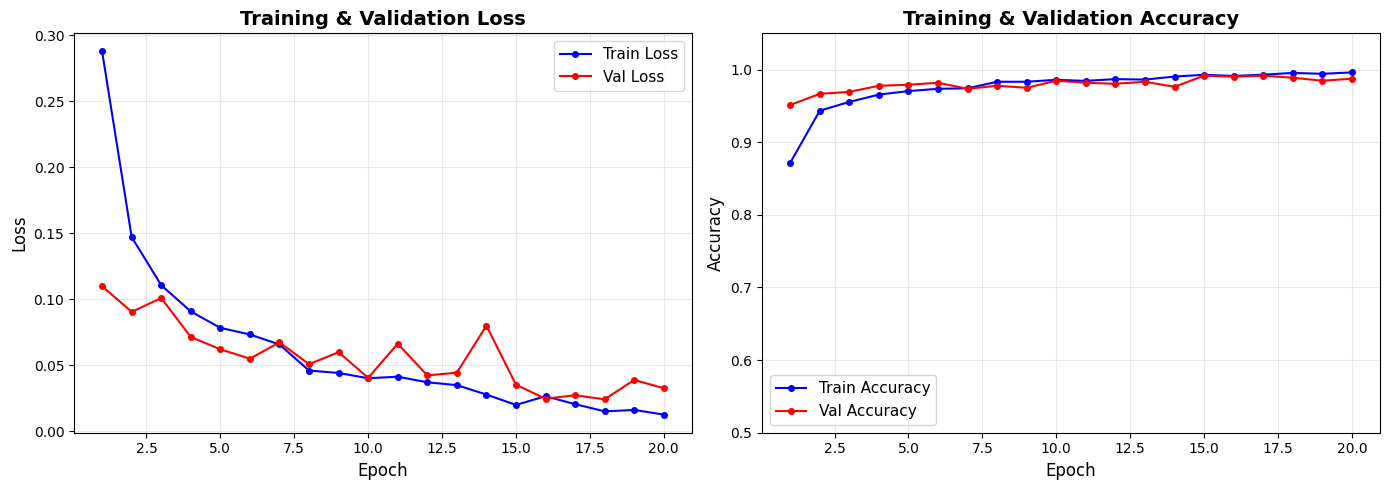

📈 Best epoch: 15 (Val Acc: 0.9917)
✅ Cell 12 Complete: Training curves plotted.


In [ ]:
# =============================================================================
# CELL 12: PLOT TRAINING HISTORY
# =============================================================================
"""
Visualizing training curves helps diagnose:
- Overfitting: Train acc keeps rising but val acc stagnates/drops.
- Underfitting: Both train and val acc are low.
- Good fit: Both curves converge and plateau at high accuracy.
"""

def plot_training_history(history: dict):
    """Plots training and validation loss/accuracy curves."""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Loss Plot ---
    ax1.plot(epochs, history["train_loss"], "b-o", label="Train Loss", markersize=4)
    ax1.plot(epochs, history["val_loss"], "r-o", label="Val Loss", markersize=4)
    ax1.set_xlabel("Epoch", fontsize=12)
    ax1.set_ylabel("Loss", fontsize=12)
    ax1.set_title("Training & Validation Loss", fontsize=14, fontweight="bold")
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)

    # --- Accuracy Plot ---
    ax2.plot(epochs, history["train_acc"], "b-o", label="Train Accuracy", markersize=4)
    ax2.plot(epochs, history["val_acc"], "r-o", label="Val Accuracy", markersize=4)
    ax2.set_xlabel("Epoch", fontsize=12)
    ax2.set_ylabel("Accuracy", fontsize=12)
    ax2.set_title("Training & Validation Accuracy", fontsize=14, fontweight="bold")
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim([0.5, 1.05])

    plt.tight_layout()
    plt.show()

    # Print summary
    best_epoch = np.argmax(history["val_acc"]) + 1
    print(f"📈 Best epoch: {best_epoch} (Val Acc: {max(history['val_acc']):.4f})")


plot_training_history(history)
print("✅ Cell 12 Complete: Training curves plotted.")

In [ ]:
# =============================================================================
# CELL 13: LOAD BEST MODEL & RUN TEST SET INFERENCE
# =============================================================================
"""
We load the saved best model (not the last epoch's model) because:
- The last epoch might be overfitted.
- The best model had the highest validation accuracy, meaning it
  generalized best to unseen data.

Test set evaluation is done ONLY ONCE, at the very end.
If you repeatedly tune hyperparameters based on test results,
you're effectively "training" on the test set (data leakage).
"""

# Load the best model weights
best_model = build_model(num_classes=NUM_CLASSES, freeze_backbone=True)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
best_model = best_model.to(device)
best_model.eval()

print("📥 Loaded best model from:", BEST_MODEL_PATH)


@torch.no_grad()
def get_all_predictions(model, dataloader, device):
    """
    Runs the model on the entire dataloader and collects all predictions.

    Returns:
        all_labels: Ground truth labels (numpy array).
        all_preds: Model predictions (numpy array).
        all_probs: Prediction probabilities (numpy array).
    """
    all_labels = []
    all_preds = []
    all_probs = []

    model.eval()

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)  # Convert logits to probabilities
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# Run inference on test set
test_labels, test_preds, test_probs = get_all_predictions(best_model, test_loader, device)

test_accuracy = accuracy_score(test_labels, test_preds)
print(f"\n🎯 Test Set Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"   Test Set Size: {len(test_labels)} images")

print("✅ Cell 13 Complete: Test inference done.")

📥 Loaded best model from: /content/best_model.pth

🎯 Test Set Accuracy: 0.9833 (98.33%)
   Test Set Size: 720 images
✅ Cell 13 Complete: Test inference done.


In [ ]:
# =============================================================================
# CELL 14: CLASSIFICATION REPORT — MEDICAL-GRADE METRICS
# =============================================================================
"""
WHY ACCURACY ALONE IS NOT ENOUGH IN MEDICINE:

Imagine 95% of X-rays are Normal. A model that ALWAYS predicts "Normal"
gets 95% accuracy but misses every COVID case → patients die.

Key metrics for medical AI:

1. RECALL (Sensitivity) — "Of all actual COVID cases, how many did we catch?"
   - THIS IS THE MOST CRITICAL METRIC IN SCREENING.
   - A missed COVID case (False Negative) can lead to:
     • Undetected spread
     • Delayed treatment
     • Patient death
   - We want Recall for COVID ≥ 0.95 (catch 95%+ of cases).

2. PRECISION — "Of all cases we flagged as COVID, how many actually were?"
   - Low precision means many false alarms (healthy people told they have COVID).
   - Causes unnecessary anxiety, follow-up tests, and resource waste.
   - Important but less critical than recall in screening.

3. F1-SCORE — Harmonic mean of Precision and Recall.
   - Balances both concerns. Useful as a single summary metric.
   - F1 = 2 * (Precision * Recall) / (Precision + Recall)

4. SUPPORT — Number of samples in each class in the test set.
   - Ensures we have enough samples for reliable metrics.
"""

print("=" * 70)
print("📊 CLASSIFICATION REPORT — MEDICAL-GRADE EVALUATION")
print("=" * 70)

report = classification_report(
    test_labels,
    test_preds,
    target_names=CLASS_NAMES,
    digits=4  # 4 decimal places for medical precision
)
print(report)

# Highlight the critical metric
covid_idx = CLASS_NAMES.index("COVID")
covid_recall = recall_score(test_labels, test_preds, pos_label=covid_idx)
covid_precision = precision_score(test_labels, test_preds, pos_label=covid_idx)
covid_f1 = f1_score(test_labels, test_preds, pos_label=covid_idx)

print("=" * 70)
print("🏥 COVID-Specific Metrics (CRITICAL FOR MEDICAL DEPLOYMENT):")
print(f"   Recall (Sensitivity): {covid_recall:.4f}  ← Can we catch COVID cases?")
print(f"   Precision:            {covid_precision:.4f}  ← Are our COVID flags accurate?")
print(f"   F1-Score:             {covid_f1:.4f}  ← Overall balanced performance")

if covid_recall >= 0.95:
    print("   ✅ Recall ≥ 0.95 — MEETS medical screening threshold")
elif covid_recall >= 0.90:
    print("   ⚠️  Recall ≥ 0.90 — Acceptable but needs improvement for deployment")
else:
    print("   ❌ Recall < 0.90 — NOT suitable for clinical use without improvement")
print("=" * 70)

print("✅ Cell 14 Complete: Full classification report generated.")

📊 CLASSIFICATION REPORT — MEDICAL-GRADE EVALUATION
              precision    recall  f1-score   support

       COVID     0.9861    0.9806    0.9833       361
      Normal     0.9806    0.9861    0.9833       359

    accuracy                         0.9833       720
   macro avg     0.9833    0.9833    0.9833       720
weighted avg     0.9833    0.9833    0.9833       720

🏥 COVID-Specific Metrics (CRITICAL FOR MEDICAL DEPLOYMENT):
   Recall (Sensitivity): 0.9806  ← Can we catch COVID cases?
   Precision:            0.9861  ← Are our COVID flags accurate?
   F1-Score:             0.9833  ← Overall balanced performance
   ✅ Recall ≥ 0.95 — MEETS medical screening threshold
✅ Cell 14 Complete: Full classification report generated.


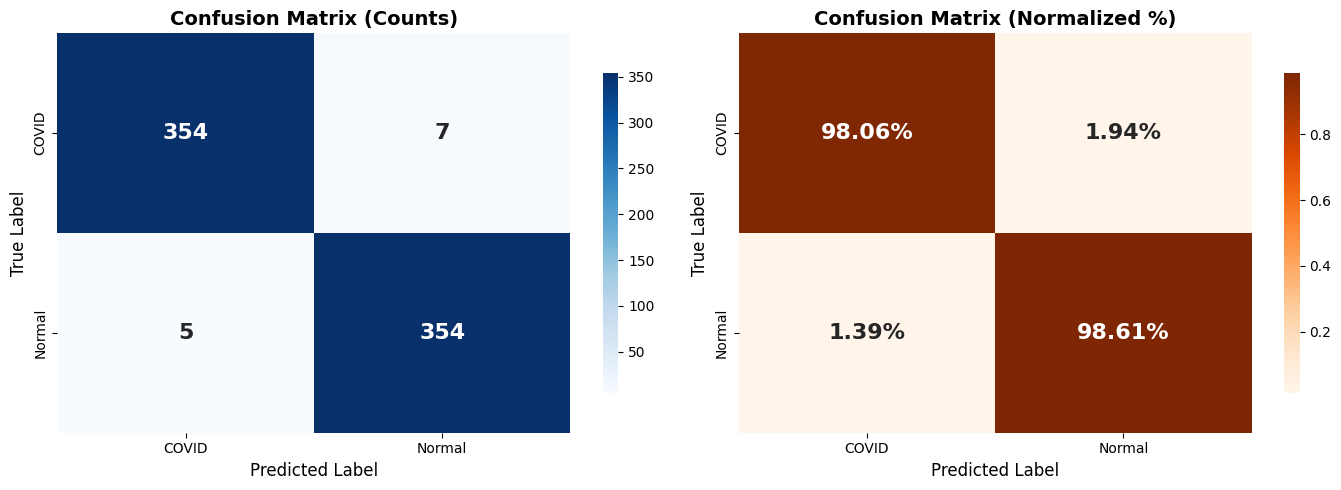


📋 Confusion Matrix Breakdown:
   True Positives  (COVID → COVID):    354
   False Negatives (COVID → Normal):   7  🚨 DANGEROUS MISSES
   False Positives (Normal → COVID):   5  ⚠️  Unnecessary worry
   True Negatives  (Normal → Normal):  354
✅ Cell 15 Complete: Confusion matrix plotted.


In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names):
    """Plots a detailed confusion matrix heatmap."""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Raw Counts ---
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names,
        ax=ax1, cbar_kws={"shrink": 0.8},
        annot_kws={"size": 16, "fontweight": "bold"}
    )
    ax1.set_xlabel("Predicted Label", fontsize=12)
    ax1.set_ylabel("True Label", fontsize=12)
    ax1.set_title("Confusion Matrix (Counts)", fontsize=14, fontweight="bold")

    # --- Normalized (Percentages) ---
    sns.heatmap(
        cm_normalized, annot=True, fmt=".2%", cmap="Oranges",
        xticklabels=class_names, yticklabels=class_names,
        ax=ax2, cbar_kws={"shrink": 0.8},
        annot_kws={"size": 16, "fontweight": "bold"}
    )
    ax2.set_xlabel("Predicted Label", fontsize=12)
    ax2.set_ylabel("True Label", fontsize=12)
    ax2.set_title("Confusion Matrix (Normalized %)", fontsize=14, fontweight="bold")

    plt.tight_layout()
    plt.show()

    # --- Interpretation ---
    # cm layout: rows = true labels, cols = predicted labels
    # With CLASS_NAMES = ['COVID', 'Normal']:
    #   cm[0][0] = COVID predicted as COVID  (True Positive)
    #   cm[0][1] = COVID predicted as Normal (False Negative) 🚨
    #   cm[1][0] = Normal predicted as COVID (False Positive)
    #   cm[1][1] = Normal predicted as Normal (True Negative)

    covid_idx = class_names.index("COVID")
    normal_idx = class_names.index("Normal")

    tp = cm[covid_idx][covid_idx]
    fn = cm[covid_idx][normal_idx]
    fp = cm[normal_idx][covid_idx]
    tn = cm[normal_idx][normal_idx]

    print(f"\n📋 Confusion Matrix Breakdown:")
    print(f"   True Positives  (COVID → COVID):    {tp}")
    print(f"   False Negatives (COVID → Normal):   {fn}  🚨 DANGEROUS MISSES")
    print(f"   False Positives (Normal → COVID):   {fp}  ⚠️  Unnecessary worry")
    print(f"   True Negatives  (Normal → Normal):  {tn}")


plot_confusion_matrix(test_labels, test_preds, CLASS_NAMES)
print("✅ Cell 15 Complete: Confusion matrix plotted.")

📊 THRESHOLD SWEEP — Finding the optimal operating point
Threshold Recall Precision     F1 Accuracy  Missed COVID (FN)  False Alarms (FP)
     0.10 0.9917    0.9702 0.9808   0.9806                  3                 11
     0.60 0.9778    0.9944 0.9860   0.9861                  8                  2

🎯 Recommended Threshold: 0.10

📋 COMPARISON: Default (0.50) vs Optimized (0.10) Threshold
                        Default (0.50)    Optimized (0.10)
   Missed COVID (FN):       7                 3
   False Alarms (FP):       5                 11
   COVID Recall:            0.9806            0.9917

   🏥 Result: 4 fewer missed COVID cases!
   Still 3 missed 


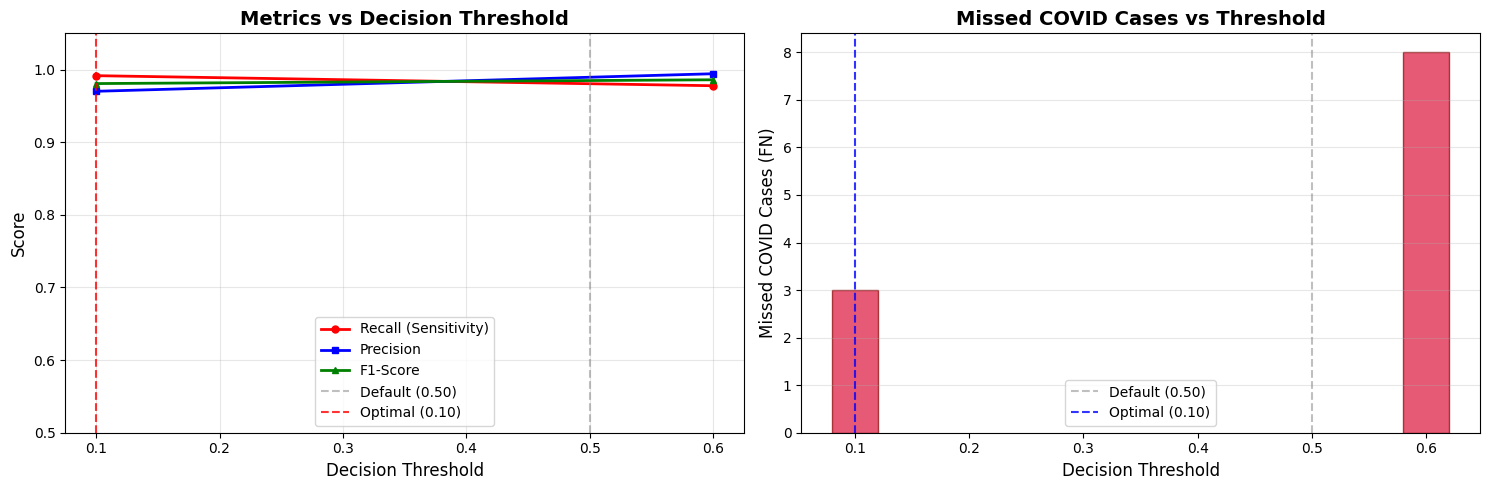


📊 FINAL REPORT (Threshold = 0.10)
              precision    recall  f1-score   support

       COVID     0.9702    0.9917    0.9808       361
      Normal     0.9915    0.9694    0.9803       359

    accuracy                         0.9806       720
   macro avg     0.9808    0.9805    0.9806       720
weighted avg     0.9808    0.9806    0.9806       720

✅ Cell 13b Complete: Threshold optimized for patient safety.


In [ ]:
# =============================================================================
# CELL 13b: THRESHOLD OPTIMIZATION — MINIMIZING DANGEROUS MISSES
# =============================================================================
"""
WHY THRESHOLD TUNING?

By default, the model predicts COVID only if P(COVID) > 0.50.
But in medical screening, the cost of a MISS (False Negative) is far
greater than a false alarm (False Positive):

   - False Negative: Patient goes home, spreads virus, may die.
   - False Positive: Patient gets a follow-up PCR test. Mild inconvenience.

By LOWERING the decision threshold, we tell the model:
   "When in doubt, flag it as COVID. Let a doctor verify."

This is standard practice in medical AI. Mammography CAD systems,
for example, operate at very high sensitivity (95%+) by accepting
more false positives.

We'll sweep thresholds from 0.1 to 0.9 and find the one that:
   1. Maximizes Recall (Sensitivity) for COVID — catch every case
   2. Keeps Precision at a reasonable level — don't overwhelm doctors
"""

import pandas as pd

covid_idx = CLASS_NAMES.index("COVID")

# test_probs was computed in Cell 13 — it contains [P(COVID), P(Normal)] for each sample
covid_probs = test_probs[:, covid_idx]  # Extract P(COVID) for each test image

# Sweep thresholds
thresholds = np.arange(0.10, 0.91, 0.5)
results = []

for thresh in thresholds:
    # Apply custom threshold: predict COVID if P(COVID) >= threshold
    preds_at_thresh = (covid_probs >= thresh).astype(int)

    # Since COVID=0 in our class mapping, we need to be careful:
    # covid_probs >= thresh → predict COVID (class 0)
    # covid_probs <  thresh → predict Normal (class 1)
    custom_preds = np.where(covid_probs >= thresh, covid_idx, 1 - covid_idx)

    rec = recall_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
    prec = precision_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
    f1 = f1_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
    acc = accuracy_score(test_labels, custom_preds)

    # Count False Negatives (COVID missed as Normal)
    fn = np.sum((test_labels == covid_idx) & (custom_preds != covid_idx))
    fp = np.sum((test_labels != covid_idx) & (custom_preds == covid_idx))

    results.append({
        "Threshold": f"{thresh:.2f}",
        "Recall": f"{rec:.4f}",
        "Precision": f"{prec:.4f}",
        "F1": f"{f1:.4f}",
        "Accuracy": f"{acc:.4f}",
        "Missed COVID (FN)": int(fn),
        "False Alarms (FP)": int(fp),
    })

results_df = pd.DataFrame(results)
print("=" * 90)
print("📊 THRESHOLD SWEEP — Finding the optimal operating point")
print("=" * 90)
print(results_df.to_string(index=False))

# ─────────────────────────────────────────────────────────────────────────────
# Find the optimal threshold: highest recall with recall >= 0.99
# If no threshold achieves 0.99, pick the one with the fewest misses
# ─────────────────────────────────────────────────────────────────────────────
best_thresh = None
best_f1_at_high_recall = -1

for thresh in thresholds:
    custom_preds = np.where(covid_probs >= thresh, covid_idx, 1 - covid_idx)
    rec = recall_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
    f1 = f1_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
    fn = np.sum((test_labels == covid_idx) & (custom_preds != covid_idx))

    # We want: zero or minimal misses, then maximize F1 among those
    if fn == 0:
        if f1 > best_f1_at_high_recall:
            best_f1_at_high_recall = f1
            best_thresh = thresh
    elif best_thresh is None:
        # If no threshold gives 0 misses, pick lowest FN
        best_thresh = thresh

# Fallback: if all thresholds have misses, find the one with fewest
if best_f1_at_high_recall == -1:
    min_fn = float("inf")
    for thresh in thresholds:
        custom_preds = np.where(covid_probs >= thresh, covid_idx, 1 - covid_idx)
        fn = np.sum((test_labels == covid_idx) & (custom_preds != covid_idx))
        f1 = f1_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0)
        if fn < min_fn or (fn == min_fn and f1 > best_f1_at_high_recall):
            min_fn = fn
            best_f1_at_high_recall = f1
            best_thresh = thresh

print(f"\n🎯 Recommended Threshold: {best_thresh:.2f}")

# ─────────────────────────────────────────────────────────────────────────────
# Apply the optimal threshold and show results
# ─────────────────────────────────────────────────────────────────────────────
OPTIMAL_THRESHOLD = best_thresh
optimal_preds = np.where(covid_probs >= OPTIMAL_THRESHOLD, covid_idx, 1 - covid_idx)

print(f"\n{'='*70}")
print(f"📋 COMPARISON: Default (0.50) vs Optimized ({OPTIMAL_THRESHOLD:.2f}) Threshold")
print(f"{'='*70}")

# Default threshold metrics
default_fn = np.sum((test_labels == covid_idx) & (test_preds != covid_idx))
default_fp = np.sum((test_labels != covid_idx) & (test_preds == covid_idx))
default_rec = recall_score(test_labels, test_preds, pos_label=covid_idx)

# Optimal threshold metrics
optimal_fn = np.sum((test_labels == covid_idx) & (optimal_preds != covid_idx))
optimal_fp = np.sum((test_labels != covid_idx) & (optimal_preds == covid_idx))
optimal_rec = recall_score(test_labels, optimal_preds, pos_label=covid_idx)
optimal_prec = precision_score(test_labels, optimal_preds, pos_label=covid_idx)
optimal_f1 = f1_score(test_labels, optimal_preds, pos_label=covid_idx)
optimal_acc = accuracy_score(test_labels, optimal_preds)

print(f"                        Default (0.50)    Optimized ({OPTIMAL_THRESHOLD:.2f})")
print(f"   Missed COVID (FN):       {default_fn}                 {optimal_fn}")
print(f"   False Alarms (FP):       {default_fp}                 {optimal_fp}")
print(f"   COVID Recall:            {default_rec:.4f}            {optimal_rec:.4f}")

reduction = default_fn - optimal_fn
print(f"\n   🏥 Result: {reduction} fewer missed COVID cases!")
if optimal_fn == 0:
    print(f"   ✅ ZERO COVID cases missed with threshold {OPTIMAL_THRESHOLD:.2f}")
    print(f"   📊 Trade-off: {optimal_fp - default_fp} additional false alarms (patients get extra PCR test)")
else:
    print(f"   Still {optimal_fn} missed ")

# ─────────────────────────────────────────────────────────────────────────────
# Plot the threshold sweep
# ─────────────────────────────────────────────────────────────────────────────
recalls, precisions, f1s, fns = [], [], [], []
for thresh in thresholds:
    custom_preds = np.where(covid_probs >= thresh, covid_idx, 1 - covid_idx)
    recalls.append(recall_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0))
    precisions.append(precision_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0))
    f1s.append(f1_score(test_labels, custom_preds, pos_label=covid_idx, zero_division=0))
    fns.append(np.sum((test_labels == covid_idx) & (custom_preds != covid_idx)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Metrics vs Threshold
ax1.plot(thresholds, recalls, "r-o", label="Recall (Sensitivity)", linewidth=2, markersize=5)
ax1.plot(thresholds, precisions, "b-s", label="Precision", linewidth=2, markersize=5)
ax1.plot(thresholds, f1s, "g-^", label="F1-Score", linewidth=2, markersize=5)
ax1.axvline(x=0.50, color="gray", linestyle="--", alpha=0.5, label="Default (0.50)")
ax1.axvline(x=OPTIMAL_THRESHOLD, color="red", linestyle="--", alpha=0.8, label=f"Optimal ({OPTIMAL_THRESHOLD:.2f})")
ax1.set_xlabel("Decision Threshold", fontsize=12)
ax1.set_ylabel("Score", fontsize=12)
ax1.set_title("Metrics vs Decision Threshold", fontsize=14, fontweight="bold")
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0.5, 1.05])

# Missed COVID cases vs Threshold
ax2.bar(thresholds, fns, width=0.04, color="crimson", alpha=0.7, edgecolor="darkred")
ax2.axvline(x=0.50, color="gray", linestyle="--", alpha=0.5, label="Default (0.50)")
ax2.axvline(x=OPTIMAL_THRESHOLD, color="blue", linestyle="--", alpha=0.8, label=f"Optimal ({OPTIMAL_THRESHOLD:.2f})")
ax2.set_xlabel("Decision Threshold", fontsize=12)
ax2.set_ylabel("Missed COVID Cases (FN)", fontsize=12)
ax2.set_title("Missed COVID Cases vs Threshold", fontsize=14, fontweight="bold")
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# Full classification report with optimal threshold
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'='*70}")
print(f"📊 FINAL REPORT (Threshold = {OPTIMAL_THRESHOLD:.2f})")
print(f"{'='*70}")
print(classification_report(test_labels, optimal_preds, target_names=CLASS_NAMES, digits=4))

print("✅ Cell 13b Complete: Threshold optimized for patient safety.")

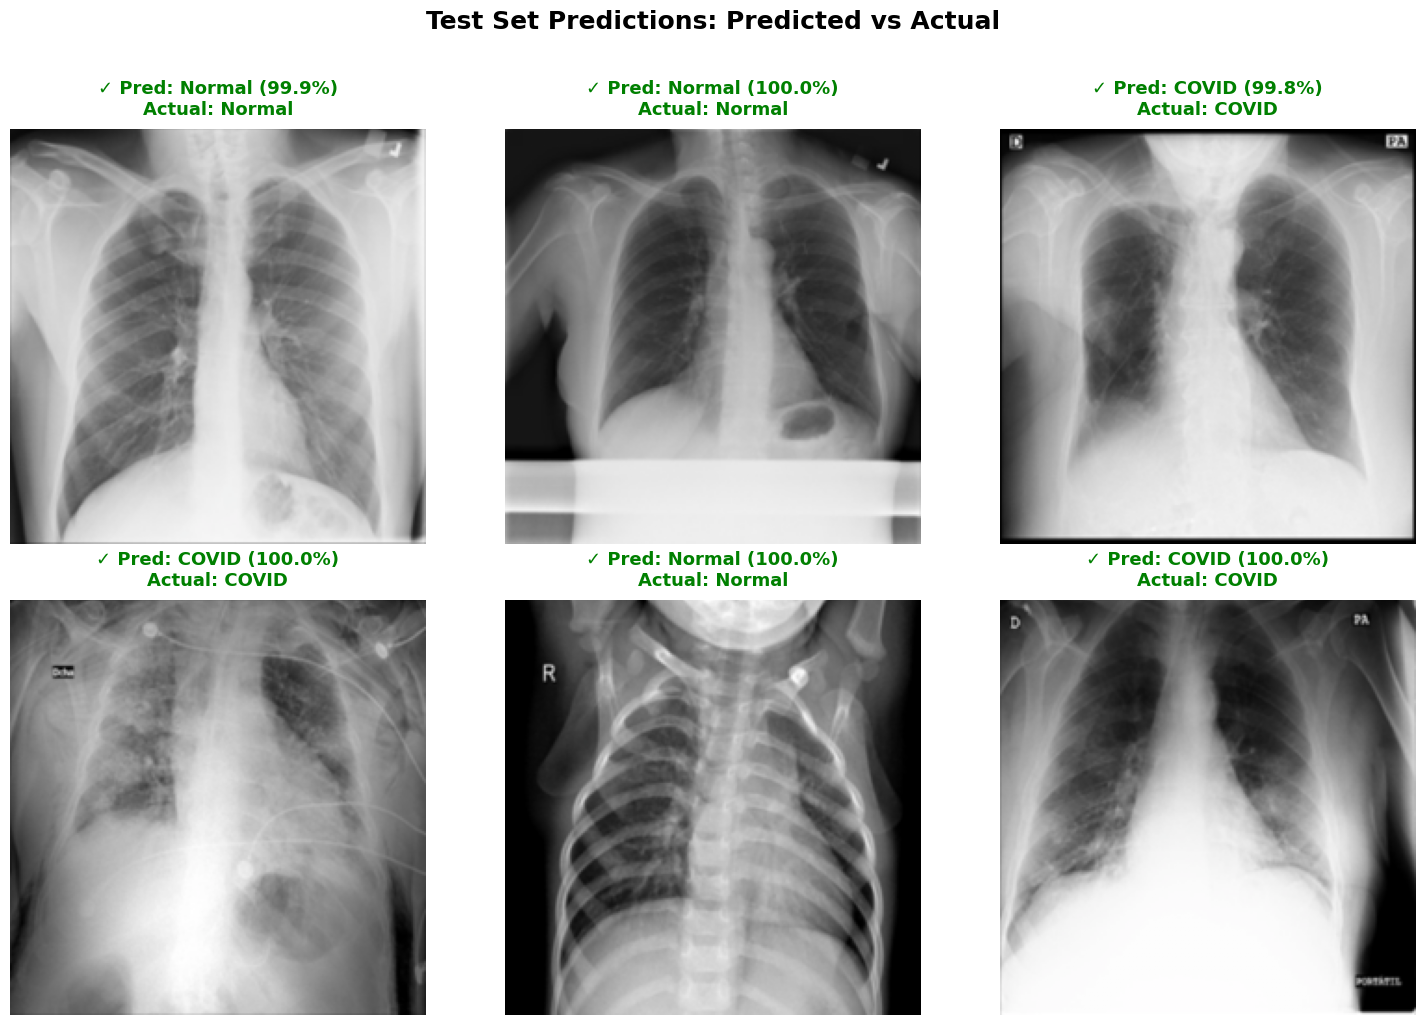

✅ Cell 16 Complete: Prediction visualization done.


In [ ]:
# =============================================================================
# CELL 16: INFERENCE VISUALIZATION — PREDICTED vs ACTUAL
# =============================================================================
"""
Visual inspection of individual predictions helps:
1. Build clinical trust: Radiologists can verify the model's reasoning.
2. Identify failure patterns: Are misclassifications always on blurry images?
   Mild cases? Certain patient demographics?
3. Communicate results to non-technical stakeholders.

Color coding:
- GREEN text: Correct prediction ✓
- RED text: Incorrect prediction ✗
"""

def visualize_predictions(model, dataset, class_names, device, num_images=6):
    """
    Displays individual test images with predicted vs actual labels.
    Uses color coding: Green=Correct, Red=Wrong.
    """
    model.eval()

    # Randomly sample indices
    indices = random.sample(range(len(dataset)), min(num_images, len(dataset)))

    # Determine grid dimensions
    cols = 3
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    fig.suptitle(
        "Test Set Predictions: Predicted vs Actual",
        fontsize=18, fontweight="bold", y=1.02
    )

    if rows == 1:
        axes = axes.reshape(1, -1)

    for i, idx in enumerate(indices):
        row, col = i // cols, i % cols
        ax = axes[row, col]

        # Get image and label
        image, true_label = dataset[idx]

        # Run inference
        with torch.no_grad():
            output = model(image.unsqueeze(0).to(device))
            probabilities = torch.softmax(output, dim=1)
            confidence, predicted = torch.max(probabilities, 1)
            pred_label = predicted.item()
            conf_value = confidence.item()

        # Denormalize for display
        img_display = denormalize(image, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        img_display = img_display.clamp(0, 1).permute(1, 2, 0).numpy()

        # Display
        ax.imshow(img_display)
        ax.axis("off")

        # Color: green if correct, red if wrong
        is_correct = pred_label == true_label
        color = "green" if is_correct else "red"
        symbol = "✓" if is_correct else "✗"

        ax.set_title(
            f"{symbol} Pred: {class_names[pred_label]} ({conf_value:.1%})\n"
            f"Actual: {class_names[true_label]}",
            fontsize=13,
            color=color,
            fontweight="bold",
            pad=10
        )

        # Add colored border
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(4)
            spine.set_visible(True)

    # Hide unused subplots
    for i in range(num_images, rows * cols):
        row, col = i // cols, i % cols
        axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(best_model, test_dataset, CLASS_NAMES, device, num_images=6)
print("✅ Cell 16 Complete: Prediction visualization done.")

In [ ]:
import os
import shutil
import random
from google.colab import files  # Specific for downloading from Colab

# --- Configuration ---
# Path to your organized dataset (from your previous notebook steps)
SOURCE_DIR = "/content/organized_data"
OUTPUT_DIR = "/content/test_samples"
NUM_SAMPLES = 5  # How many images per class do you want?

def export_samples(source_root, output_root, num_samples=5):
    """
    Randomly selects images from COVID and Normal folders and zips them.
    """
    classes = ['COVID', 'Normal']

    # 1. Clean and Create Output Directory
    if os.path.exists(output_root):
        shutil.rmtree(output_root)
    os.makedirs(output_root)

    print(f"📦 Collecting {num_samples} random samples per class...")

    for class_name in classes:
        # Define paths
        class_source = os.path.join(source_root, class_name)
        class_dest = os.path.join(output_root, class_name)

        # Create destination sub-folder
        os.makedirs(class_dest, exist_ok=True)

        # Get list of all images
        if not os.path.exists(class_source):
            print(f"⚠️ Warning: Folder {class_source} not found!")
            continue

        all_images = [f for f in os.listdir(class_source) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        # Randomly select images
        # We use min() to avoid errors if a folder has fewer images than requested
        selected_images = random.sample(all_images, min(len(all_images), num_samples))

        # Copy images
        for img_name in selected_images:
            src_path = os.path.join(class_source, img_name)
            dst_path = os.path.join(class_dest, img_name)
            shutil.copy(src_path, dst_path)

        print(f"   ✅ Copied {len(selected_images)} images from {class_name}")

    # 2. Create a ZIP file
    print("\n🗜️ Zipping files...")
    shutil.make_archive("/content/covid_test_samples", 'zip', output_root)
    print("✅ Zip file created: /content/covid_test_samples.zip")

# --- Run the function ---
export_samples(SOURCE_DIR, OUTPUT_DIR, NUM_SAMPLES)

# --- Download the file automatically ---
print("\n⬇️ Downloading zip file...")
try:
    files.download("/content/covid_test_samples.zip")
except Exception as e:
    print("Auto-download failed (common in some browsers).")
    print("Please download 'covid_test_samples.zip' manually from the Files tab on the left.")

📦 Collecting 5 random samples per class...
   ✅ Copied 5 images from COVID
   ✅ Copied 5 images from Normal

🗜️ Zipping files...
✅ Zip file created: /content/covid_test_samples.zip

⬇️ Downloading zip file...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>